In [3]:
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
import matplotlib.pyplot as plt

In [4]:
# Update these paths
CSV_PATH = '/Users/shubhbhateja/College/minor_project/NeoJaundice/chd_jaundice_published_2.csv'
IMAGE_DIR = '/Users/shubhbhateja/College/minor_project/images'

# Paper Specifications
INPUT_SIZE = (128, 128)
SEQ_LEN = 128 * 128 # 16,384 features per channel

In [5]:
def professional_white_balance(img):
    """Calibrates colors using Gray World algorithm before cropping."""
    result = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    avg_a = np.average(result[:, :, 1])
    avg_b = np.average(result[:, :, 2])
    result[:, :, 1] = result[:, :, 1] - ((avg_a - 128) * (result[:, :, 0] / 255.0) * 1.1)
    result[:, :, 2] = result[:, :, 2] - ((avg_b - 128) * (result[:, :, 0] / 255.0) * 1.1)
    return cv2.cvtColor(result, cv2.COLOR_LAB2BGR)

def adaptive_crop_skin(image_rgb):
    """Isolates skin patch and removes borders/background."""
    h, w = image_rgb.shape[:2]
    img_ycrcb = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2YCrCb)
    mask = cv2.inRange(img_ycrcb, np.array([0, 133, 77]), np.array([255, 173, 127]))
    
    # Clean noise
    mask[int(h*0.85):h, :] = 0 # Ignore bottom card area
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=2)
    
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours: return cv2.resize(image_rgb, INPUT_SIZE)
    
    x, y, w_b, h_b = cv2.boundingRect(max(contours, key=cv2.contourArea))
    # Inset crop to avoid edge shadows
    ix, iy = int(w_b*0.05), int(h_b*0.05)
    return image_rgb[y+iy:y+h_b-iy, x+ix:x+w_b-ix]

def prepare_image(img_path):
    img = cv2.imread(img_path)
    if img is None: return None
    
    # 1. Calibrate on FULL image
    balanced = professional_white_balance(img)
    rgb = cv2.cvtColor(balanced, cv2.COLOR_BGR2RGB)
    
    # 2. Crop Skin
    skin = adaptive_crop_skin(rgb)
    resized = cv2.resize(skin, INPUT_SIZE)
    hsv = cv2.cvtColor(resized, cv2.COLOR_RGB2HSV)
    
    # 3. Create 1D Sequences
    rgb_seq = np.stack([resized[:,:,0].flatten(), resized[:,:,1].flatten(), resized[:,:,2].flatten()], axis=0) / 255.0
    hsv_seq = np.stack([hsv[:,:,0].flatten(), hsv[:,:,1].flatten(), hsv[:,:,2].flatten()], axis=0) / 255.0
    return rgb_seq, hsv_seq

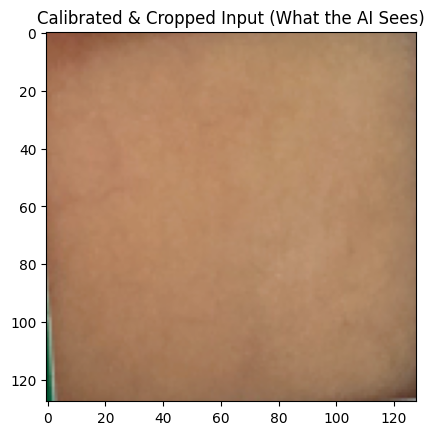

In [6]:
df = pd.read_csv(CSV_PATH)
sample_path = os.path.join(IMAGE_DIR, df.iloc[10]['image_idx'])
rgb_s, hsv_s = prepare_image(sample_path)
plt.imshow(rgb_s.T.reshape(128,128,3))
plt.title("Calibrated & Cropped Input (What the AI Sees)")
plt.show()

In [7]:
X_rgb, X_hsv, Y_treat = [], [], []

print("Processing images...")
for idx, row in df.iterrows():
    path = os.path.join(IMAGE_DIR, row['image_idx'])
    data = prepare_image(path)
    if data:
        X_rgb.append(data[0]); X_hsv.append(data[1])
        Y_treat.append(row['Treatment'])
    if idx % 200 == 0: print(f"Processed {idx}...")

X_rgb, X_hsv, Y_treat = np.array(X_rgb), np.array(X_hsv), np.array(Y_treat)
X_rgb_tr, X_rgb_ts, X_hsv_tr, X_hsv_ts, y_tr, y_ts = train_test_split(X_rgb, X_hsv, Y_treat, test_size=0.2, random_state=42)

Processing images...
Processed 0...
Processed 200...
Processed 400...
Processed 600...
Processed 800...
Processed 1000...
Processed 1200...
Processed 1400...
Processed 1600...
Processed 1800...
Processed 2000...
Processed 2200...


In [8]:
def build_classification_model():
    def branch(name):
        inp = layers.Input(shape=(3, SEQ_LEN), name=name)
        x = layers.Conv1D(32, 3, padding='same', activation='relu')(inp)
        x = layers.MaxPooling1D(2, padding='same')(x)
        x = layers.Conv1D(64, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling1D(2, padding='same')(x)
        x = layers.Conv1D(128, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling1D(2, padding='same')(x)
        return inp, layers.Flatten()(x)

    rgb_in, rgb_f = branch("rgb_input")
    hsv_in, hsv_f = branch("hsv_input")
    merged = layers.Concatenate()([rgb_f, hsv_f])
    x = layers.Dense(256, activation='relu')(merged)
    x = layers.Dropout(0.4)(x) # High dropout helps prevent overfitting to light noise
    x = layers.Dense(128, activation='relu')(x)
    out = layers.Dense(1, activation='sigmoid', name='treatment_output')(x)

    model = models.Model(inputs=[rgb_in, hsv_in], outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

model = build_classification_model()

In [9]:
# Calculate weights to handle imbalance
weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_tr), y=y_tr)
dict_weights = {0: weights[0], 1: weights[1]}

# LR Scheduler to handle underfitting and find the global minimum
def lr_schedule(epoch):
    lr = 1e-3
    if epoch > 50: lr *= 0.1
    return lr

history = model.fit(
    x={'rgb_input': X_rgb_tr, 'hsv_input': X_hsv_tr},
    y=y_tr,
    validation_data=({'rgb_input': X_rgb_ts, 'hsv_input': X_hsv_ts}, y_ts),
    epochs=100,
    batch_size=16, # Small batches help 1DCNN catch subtle sequences
    class_weight=dict_weights,
    callbacks=[tf.keras.callbacks.LearningRateScheduler(lr_schedule)]
)

Epoch 1/100
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.4843 - loss: 0.9275 - val_accuracy: 0.6040 - val_loss: 0.6898 - learning_rate: 0.0010
Epoch 2/100
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5687 - loss: 0.6955 - val_accuracy: 0.6040 - val_loss: 0.6915 - learning_rate: 0.0010
Epoch 3/100
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4949 - loss: 0.6951 - val_accuracy: 0.6040 - val_loss: 0.6927 - learning_rate: 0.0010
Epoch 4/100
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5477 - loss: 0.6920 - val_accuracy: 0.3960 - val_loss: 0.6939 - learning_rate: 0.0010
Epoch 5/100
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4757 - loss: 0.6948 - val_accuracy: 0.6040 - val_loss: 0.6931 - learning_rate: 0.0010
Epoch 6/100
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5385 - loss: 0.6946 - val_accuracy: 0.3960 - val_loss: 0.6933 - learning_rate: 0.0010
Epoch 7/100
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5572 - los

In [11]:
# Handle class imbalance
weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_tr), y=y_tr)
dict_weights = {0: weights[0], 1: weights[1]}

# LR Scheduler to find the global minimum for color detection
def lr_schedule(epoch):
    lr = 1e-3
    if epoch > 50: lr *= 0.1
    return lr

print("Starting balanced classification training...")
history = model.fit(
    x={'rgb_input': X_rgb_tr, 'hsv_input': X_hsv_tr},
    y=y_tr,
    validation_data=({'rgb_input': X_rgb_ts, 'hsv_input': X_hsv_ts}, y_ts),
    epochs=200,
    batch_size=16, 
    class_weight=dict_weights,
    callbacks=[tf.keras.callbacks.LearningRateScheduler(lr_schedule)],
    verbose=1
)

Starting balanced classification training...
Epoch 1/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5042 - loss: 0.6894 - val_accuracy: 0.6040 - val_loss: 0.6928 - learning_rate: 0.0010
Epoch 2/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5420 - loss: 0.6911 - val_accuracy: 0.6040 - val_loss: 0.6929 - learning_rate: 0.0010
Epoch 3/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4797 - loss: 0.6950 - val_accuracy: 0.3960 - val_loss: 0.6932 - learning_rate: 0.0010
Epoch 4/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.4756 - loss: 0.6937 - val_accuracy: 0.6040 - val_loss: 0.6931 - learning_rate: 0.0010
Epoch 5/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4830 - loss: 0.6936 - val_accuracy: 0.3960 - val_loss: 0.6936 - learning_rate: 0.0010
Epoch 6/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5161 - loss: 0.6902 - val_accuracy: 0.6040 - val_loss: 0.6929 - learning_rate: 0.0010
Epoch 7/200
112/112 ━━━━━━━━━━━━━